# Análise Comparativa de Arquiteturas Neuronais na Deteção de Sopros Cardíacos

### Aprendizagem Computacional II — CC3043

**Elementos do grupo:**
- Nome: Ana Alves — N.º mecanográfico: `[Número]`
- Nome: Lara Queiroga — N.º mecanográfico: `[Número]`
- Nome: `[Nome do elemento 3]` — N.º mecanográfico: `[Número]`

> **Notas internas do grupo (apagar antes da entrega)**
>
> - **Padding:** usar repetição ou *mirroring* e ver se há mais padding numa classe do que noutra. *Estado:* com os dados atuais não há padding nenhum (todas as gravações têm ≥ 5 s e a cauda incompleta é descartada); ver 5.2.1 e 5.5.2.
> - **Unknown:** criar um modelo que identifique primeiro os `Unknown` e só depois tratar os outros dois (escolher o melhor modelo). **Só depois remover as janelas ruidosas.** *Estado:* pendente; a filtragem de janelas ruidosas está desativada no Anexo A.

---

## 1. Introdução

A auscultação cardíaca permite identificar sons associados ao funcionamento do coração, podendo revelar a presença de sopros cardíacos. A análise automática de gravações de áudio constitui, por isso, uma possível abordagem de apoio à identificação destes sinais.

Neste trabalho será utilizado o conjunto de dados **CirCor DigiScope**, que contém gravações de sons cardíacos obtidas em diferentes locais de auscultação, acompanhadas de informação clínica e de anotações relativas aos pacientes.

O objetivo é desenvolver e comparar modelos de redes neuronais capazes de classificar os pacientes em três categorias: `Present`, `Absent` e `Unknown`, correspondentes à presença, ausência ou incerteza relativamente à existência de um sopro cardíaco.

Inicialmente, serão consideradas três arquiteturas — *Multilayer Perceptron* (MLP), *Convolutional Neural Network* (CNN) e *Recurrent Neural Network* (RNN). O objetivo é analisar as suas características e selecionar duas abordagens para implementação, tendo em conta a natureza dos dados, a complexidade dos modelos e a possibilidade de comparar diferentes representações do áudio.

---

## 2. Decisões iniciais

### 2.1. Seleção das arquiteturas

Os dois modelos que decidimos implementar foram os seguintes:
- **RNN — excluída:** apesar de ser adequada à modelação de sequências temporais, a sua utilização não é prioritária neste problema. As CNN permitem explorar padrões acústicos locais e estruturas relevantes dos sons cardíacos através de convoluções.
- **MLP — selecionada:** será utilizada como abordagem de referência, recebendo características acústicas extraídas previamente das gravações.
- **CNN — selecionada:** será utilizada para aprender padrões diretamente a partir de uma representação tempo-frequência do áudio.

Esta seleção permite comparar duas estratégias de representação dos dados, sem implementar modelos em excesso.

### 2.2. Comparação das representações do áudio

A comparação entre a MLP e a CNN pretende estudar se é mais vantajoso fornecer ao modelo características acústicas previamente calculadas ou uma representação mais completa do sinal.

| Aspeto | MLP | CNN 2D |
|---|---|---|
| Entrada | Vetor de características acústicas | Espectrograma Mel |
| Pré-processamento | Extração de características | Transformação do áudio em espectrograma |
| Aprendizagem | Relações entre características calculadas | Padrões locais no tempo e na frequência |
| Vantagem principal | Representação compacta e interpretável | Aprendizagem automática de padrões tempo-frequência |

Para a MLP poderão ser extraídas características como a energia do sinal, o centróide espectral e os coeficientes MFCC (*Mel-Frequency Cepstral Coefficients*), recorrendo a estatísticas que resumam a sua distribuição ao longo do tempo.

Na CNN, cada janela de áudio (segmento de comprimento fixo de uma gravação) será transformada num **espectrograma Mel**, que representa a evolução da energia nas diferentes bandas de frequência ao longo do tempo. Esta representação preserva informação temporal e espectral que a rede poderá utilizar para aprender padrões relevantes para a classificação.

### 2.3. Escolha da CNN 2D em vez da CNN 1D

As CNN 1D processam diretamente a sequência de amplitudes do áudio, aplicando convoluções ao longo do tempo. Embora esta abordagem permita aprender a partir da forma de onda original, pode exigir que a rede aprenda representações acústicas úteis a partir de um sinal de elevada dimensionalidade.

As CNN 2D, por sua vez, processam espectrogramas, aplicando convoluções nas dimensões temporal e frequencial. Esta representação torna explícita a distribuição da energia pelas frequências e a sua evolução ao longo do tempo.

Assim, opta-se pela **CNN 2D** por permitir explorar uma representação tempo-frequência adequada à análise de sinais acústicos e compará-la com a abordagem baseada em características manuais utilizada pela MLP.

Esta decisão não pressupõe que a CNN 2D seja necessariamente superior à CNN 1D; representa uma escolha metodológica para o estudo proposto.

### 2.4. Modelos finais

Os modelos a implementar serão, portanto:

1. **MLP:** recebe características acústicas extraídas das gravações.
2. **CNN 2D:** recebe espectrogramas Mel derivados das mesmas gravações.

A comparação permitirá avaliar o impacto da representação dos dados no desempenho da classificação.

---

## 3. Imports e configuração

Bibliotecas usadas ao longo do notebook e localização do dataset.

> O dataset deve estar na mesma pasta do notebook (a pasta descarregada do PhysioNet, com `training_data.csv` e a pasta `training_data/`). O código procura o ficheiro `training_data.csv` automaticamente.

In [2]:
import os, glob, pickle
import re
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score, precision_recall_curve, f1_score
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader



# --- localizar o dataset (basta estar na mesma pasta do notebook) ---
_found = glob.glob("**/training_data.csv", recursive=True)
assert _found, "training_data.csv não encontrado: colocar a pasta do dataset junto ao notebook."
CSV = _found[0]
ROOT = os.path.dirname(CSV)
AUDIO_DIR = os.path.join(ROOT, "training_data")
print("Dataset em:", ROOT)

SEED = 42
CLASSES = ["Present", "Unknown", "Absent"]

Dataset em: the-circor-digiscope-phonocardiogram-dataset-1.0.3


---

## 4. Exploração dos dados

Antes de definir o pré-processamento, é necessário perceber o que existe no dataset. 
- Quantos pacientes há em cada classe (`Present`, `Unknown`, `Absent`)? O desequilíbrio é grande?
- Quantas gravações tem cada paciente e quais as suas durações?
- Em que focos de auscultação (AV, PV, TV, MV) existem gravações, e como se distribuem por classe?

### 4.1 Tabelas por paciente e por gravação

Criamos duas tabelas: `pat` (uma linha por **paciente**, é onde está a label `Murmur` e a coluna `Murmur locations`) e `rec` (uma linha por **gravação** `.wav`, com foco de auscultação, frequência de amostragem e duração lida do cabeçalho). Esta distinção é importante: a label vem do paciente, mas o áudio vem das gravações.

In [3]:
# Tabela por paciente (1 linha = 1 paciente; é aqui que está a label)
meta = pd.read_csv(CSV).rename(columns={"Patient ID": "patient_id"})
pat = meta[["patient_id", "Murmur", "Murmur locations"]].copy()
print(pat["Murmur"].value_counts())

# Tabela por gravação (1 linha = 1 ficheiro .wav)
rows = []
for f in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav"))):
    pid, loc = os.path.basename(f)[:-4].split("_")[:2]
    info = sf.info(f)
    rows.append(dict(patient_id=int(pid), loc=loc, fs=info.samplerate, dur=info.duration, path=f))
rec = pd.DataFrame(rows).merge(pat[["patient_id", "Murmur"]], on="patient_id")

print(f"\n{len(rec)} gravações de {rec.patient_id.nunique()} pacientes")
print("Frequências de amostragem presentes:", rec.fs.unique())

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64

3163 gravações de 942 pacientes
Frequências de amostragem presentes: [4000]


### 4.2 Distribuição das classes, gravações por paciente e durações

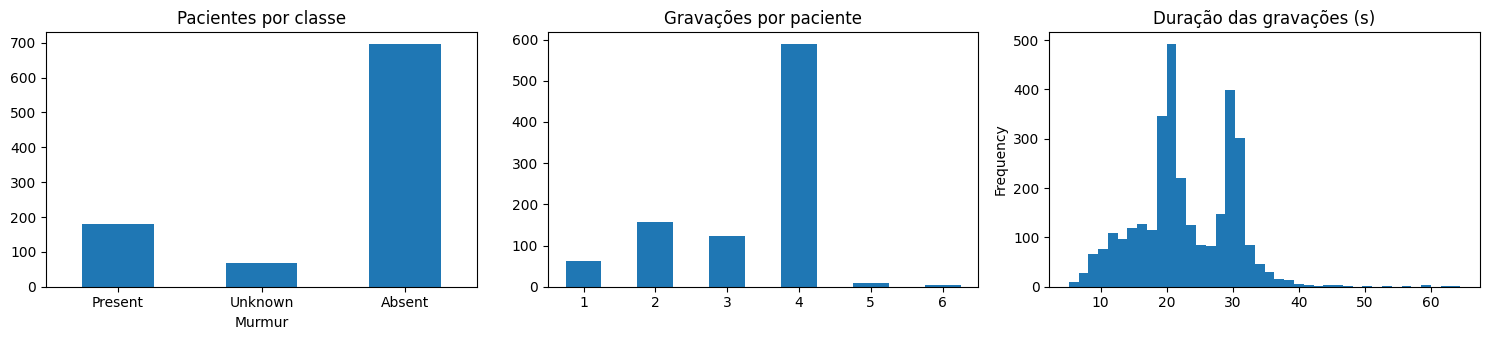

Duração (s) por classe do paciente:
          count  mean  std  min   25%   50%   75%   max
Murmur                                                 
Absent   2391.0  23.1  7.1  5.2  19.1  21.7  29.6  58.8
Present   616.0  22.3  7.9  6.4  18.2  21.0  28.6  64.5
Unknown   156.0  22.4  7.0  7.6  19.2  21.1  27.2  43.9

Gravações por foco de auscultação e classe:
Murmur  Absent  Present  Unknown
loc                             
AV         603      152       45
MV         637      172       52
PV         586      147       33
Phc          2        2        0
TV         563      143       26


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
pat["Murmur"].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], title="Pacientes por classe", rot=0)
rec.groupby("patient_id").size().value_counts().sort_index().plot.bar(ax=ax[1], title="Gravações por paciente", rot=0)
rec["dur"].plot.hist(bins=40, ax=ax[2], title="Duração das gravações (s)")
plt.tight_layout(); plt.show()

print("Duração (s) por classe do paciente:")
print(rec.groupby("Murmur")["dur"].describe().round(1))
print("\nGravações por foco de auscultação e classe:")
print(pd.crosstab(rec["loc"], rec["Murmur"]))

**O que se observa:**

- **Forte desequilíbrio entre classes:** cerca de 74% dos pacientes são `Absent`, 19% `Present` e 7% `Unknown`. Um classificador que preveja sempre `Absent` teria *accuracy* alta mas WA baixa (secção 6), por isso será preciso compensar o desequilíbrio e avaliar por classe e não só pela *accuracy*.
- **A duração não distingue as classes:** a duração média das gravações é muito semelhante nas três (≈ 22–23 s). A duração da gravação não é, portanto, uma pista que o modelo possa usar para "adivinhar" a label.
- **Focos de auscultação:** AV, MV, PV e TV têm números de gravações comparáveis dentro de cada classe (≈ 560–640 `Absent` e ≈ 140–170 `Present` por foco; `Unknown` tem menos, 26–52). Existe ainda um quinto foco, `Phc`, com apenas 4 gravações (secção seguinte).

### 4.3 Foco `Phc`: exclusão dos pacientes

Para além dos quatro focos habituais (AV, PV, TV, MV) aparece um foco `Phc` com apenas 4 gravações. Identificamos os pacientes a que pertencem:

In [5]:
phc_patients = sorted(rec.loc[rec["path"].str.contains("phc", case=False), "patient_id"].unique())
print("Pacientes com gravações PHC:", phc_patients)
print("Total:", len(phc_patients))

Pacientes com gravações PHC: [np.int64(50216), np.int64(50734), np.int64(84690)]
Total: 3


**Decisão: excluir estes 3 pacientes (e todas as suas gravações) do trabalho.** Justificação:

1. **O custo é desprezável:** saem 3 pacientes em 942 (0,3%): 2 `Present` e 1 `Absent` (o `Unknown` mantém-se em 68). As proporções entre classes quase não mudam (`Absent` 73,8% → 73,9%, `Present` 19,0% → 18,8%, `Unknown` 7,2%).
2. **Pipeline uniforme:** ficam só os quatro focos padrão, o que simplifica a análise por foco.

In [6]:
# Excluir pacientes com gravações PHC (ATENÇÃO isto apaga mesmo do dataset e as suas gravações)
pat = pat[~pat["patient_id"].isin(phc_patients)].copy()
rec = rec[~rec["patient_id"].isin(phc_patients)].copy()

### 4.4 Resumo da exploração (após exclusão do `Phc`)

In [7]:
# Resumo automático da exploração (os números vêm diretamente dos dados)
cls = pat["Murmur"].value_counts()
per_pat = rec.groupby("patient_id").size()
foc = rec["loc"].value_counts()
sem_rec = set(pat.patient_id) - set(rec.patient_id)

print("Distribuição das classes (pacientes): " + ", ".join(f"{c}: {cls[c]} ({100 * cls[c] / len(pat):.1f}%)" for c in CLASSES))
print(f"Gravações: {len(rec)} de {rec.patient_id.nunique()} pacientes; por paciente, média {per_pat.mean():.1f} (mín. {per_pat.min()}, máx. {per_pat.max()})")
print(f"Duração: mediana {rec.dur.median():.1f} s (mín. {rec.dur.min():.1f} s, máx. {rec.dur.max():.1f} s); {(rec.dur < 5.0).sum()} gravações com menos de {5.0:.0f} s")
print("Gravações por foco de auscultação: " + ", ".join(f"{l}: {n}" for l, n in foc.items()))
print(f"Pacientes no CSV sem nenhum ficheiro de áudio: {len(sem_rec)}")

Distribuição das classes (pacientes): Present: 177 (18.8%), Unknown: 68 (7.2%), Absent: 694 (73.9%)
Gravações: 3150 de 939 pacientes; por paciente, média 3.4 (mín. 1, máx. 6)
Duração: mediana 21.5 s (mín. 5.2 s, máx. 61.8 s); 0 gravações com menos de 5 s
Gravações por foco de auscultação: MV: 858, AV: 798, PV: 764, TV: 730
Pacientes no CSV sem nenhum ficheiro de áudio: 0


**Conclusões da exploração que condicionam o pré-processamento:**

- Todas as gravações têm pelo menos 5,15 s e 4000 Hz, o que permite janelas de 5 s sem reamostrar e sem necessidade de padding (5.2 e 5.5.2).
- O forte desequilíbrio entre classes justifica a estratificação (5.1), os pesos de classe no treino e a avaliação por WA (secção 6).
- Cada paciente tem várias gravações, logo a divisão é feita por paciente (5.1).
- Existem quatro focos de auscultação e o sopro pode estar só em alguns, o que justifica labels por gravação (5.4).

---

## 5. Pré-processamento

### 5.1 Divisão treino/validação/teste

Em vez de um único split treino/validação/teste, usamos **validação cruzada com 5 folds, feita por paciente**. Em cada iteração, um fold serve de **teste** (≈ 20% dos pacientes) e os restantes são divididos em **treino** e **validação** (85% / 15%, ou seja, ≈ 68% e ≈ 12% do total).

**Porquê:**
- **Por paciente:** todas as gravações do mesmo paciente ficam no mesmo conjunto (obrigatório; senão os resultados ficam demasiado otimistas). Como a tabela `pat` tem uma linha por paciente, dividir essa tabela já garante isto.
- **Estratificado pela classe `Murmur`:** cada fold mantém proporções de classes semelhantes, o que é importante porque `Unknown` é muito pequena.
- **Mesmos folds para MLP e CNN** (`random_state` fixo), para a comparação ser justa.
- **Normalização por fold:** as estatísticas de normalização são calculadas só com os pacientes de treino de cada fold (secção 5.6).

In [8]:
# Criar folds por paciente
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.zeros(len(pat), dtype=int)

for k, (_, test_i) in enumerate(skf.split(pat, pat["Murmur"])):
    folds[test_i] = k

pat["fold"] = folds
rec["fold"] = rec["patient_id"].map(pat.set_index("patient_id")["fold"])

def fold_patients(k, val_size=0.15):
    test_p = pat[pat.fold == k]
    rest = pat[pat.fold != k]
    tr_p, va_p = train_test_split(
        rest, test_size=val_size,
        stratify=rest["Murmur"], random_state=SEED + k
    )
    return set(tr_p.patient_id), set(va_p.patient_id), set(test_p.patient_id)

# Verificar ausência de sobreposição
for k in range(N_FOLDS):
    a, b, c = fold_patients(k)
    assert not (a & b) and not (a & c) and not (b & c)

print("Pacientes por fold (teste) e classe:")
print(pd.crosstab(pat["fold"], pat["Murmur"])[CLASSES])


Pacientes por fold (teste) e classe:
Murmur  Present  Unknown  Absent
fold                            
0            36       13     139
1            35       14     139
2            35       14     139
3            35       14     139
4            36       13     138


**Resultado:** cada fold de teste tem ≈ 188 pacientes, com 35–36 `Present`, 13–14 `Unknown` e 138–139 `Absent`, ou seja, proporções praticamente iguais entre folds e iguais às do conjunto total.

### 5.2 Segmentação em janelas

Este passo é igual para a MLP e para a CNN. Parte do ficheiro `.wav` e produz **janelas de áudio com tamanho fixo**, limpas e normalizadas.

| Passo | Valor | Justificação |
|---|---|---|
| Frequência de amostragem | 4000 Hz | É a frequência original das gravações, logo não se perde informação. O código reamostra apenas se algum ficheiro for diferente. |
| Filtro passa-banda | 25–600 Hz (Butterworth, ordem 4, sem desfasamento) | Os sons cardíacos e os sopros têm a energia concentrada em baixas frequências. Abaixo de ~25 Hz há sobretudo ruído de movimento e, acima de ~600 Hz, ruído ambiente. |
| Normalização | z-score por gravação | Os níveis de amplitude variam entre gravações (pressão do estetoscópio, ganho); assim o modelo foca-se na forma do sinal e não no volume. |
| Janela | 5 s | Um ciclo cardíaco dura cerca de 0,5–1 s, por isso 5 s contêm vários ciclos (informação suficiente para detetar um sopro). A gravação mais curta tem 5,15 s, logo todas as gravações têm pelo menos uma janela completa. |
| Passo (*hop*) | 2,5 s (50% de sobreposição) | Dá mais janelas por gravação, o que aumenta o número de exemplos sem alterar os dados. |
| Cauda final incompleta | descartada | Só se criam janelas **completas**: perde-se, no máximo, 2,5 s no fim de cada gravação (ver 5.2.1). |
| Gravações < 5 s | padding por reflexão | Previsto no código como salvaguarda, mas **nunca é ativado** neste dataset (não há gravações < 5 s). |

**Quantas janelas dá uma gravação?** Uma gravação de duração *d* (em segundos) dá ⌊(*d* − 5) / 2,5⌋ + 1 janelas. Por exemplo, a duração mediana (21,5 s) dá ⌊6,6⌋ + 1 = 7 janelas, que começam em 0; 2,5; …; 15 s. A última termina aos 20 s e os 1,5 s finais ficam de fora.

*Valores a ajustar com base nos resultados na validação (não no teste).*

In [9]:
FS = 4000                                  # frequência de amostragem alvo (Hz)
WIN_S, HOP_S = 5.0, 2.5                    # janela e passo (s)
WIN, HOP = int(WIN_S * FS), int(HOP_S * FS)
LOW, HIGH = 25, 600                        # banda do filtro (Hz)
SOS = butter(4, [LOW, HIGH], btype="band", fs=FS, output="sos")

def load_clean(path):
    """Lê o .wav, reamostra se necessário, filtra e normaliza."""
    x, fs = sf.read(path, dtype="float32")
    if fs != FS:
        x = librosa.resample(x, orig_sr=fs, target_sr=FS)
    x = sosfiltfilt(SOS, x)                # passa-banda sem desfasamento
    x = x - x.mean()
    x = x / (x.std() + 1e-8)               # z-score por gravação
    return x.astype(np.float32)


def windows(x):
    """
    Divide o sinal em janelas de WIN amostras, com passo HOP.

    - Só são criadas janelas COMPLETAS: o final da gravação que não completa
      uma janela é descartado (sempre < HOP_S segundos).
    - Só há padding (por reflexão) se a gravação inteira tiver menos de WIN
      amostras; neste dataset isso nunca acontece (duração mínima: 5,15 s).

    Devolve, para cada janela, (janela, nº de amostras adicionadas por padding).
    """
    result = []

    # Garantir pelo menos uma janela
    starts = range(0, max(1, len(x) - WIN + 1), HOP)

    for s in starts:
        w = x[s:s + WIN]
        pad_samples = WIN - len(w)

        if pad_samples > 0:
            if len(w) > 1:
                w = np.pad(w, (0, pad_samples), mode="reflect")
            else:
                w = np.pad(w, (0, pad_samples), mode="edge")

        result.append((w, pad_samples))

    return result


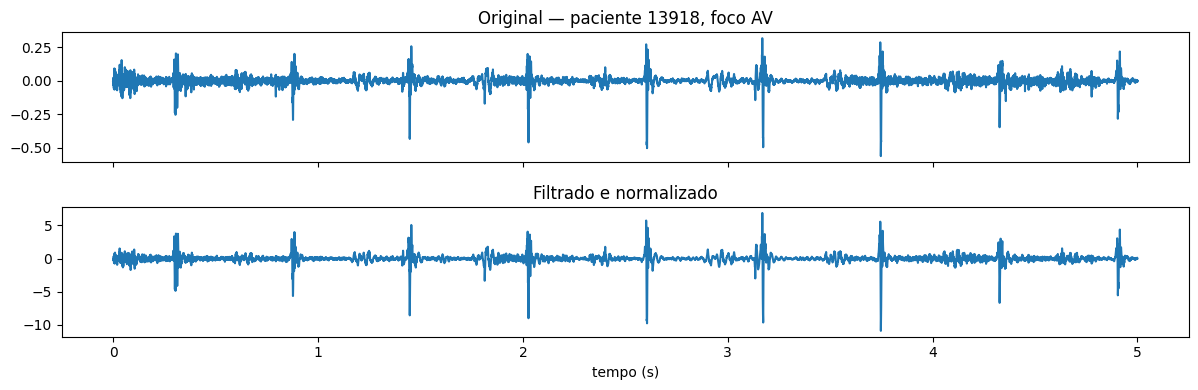

Número aproximado de janelas no dataset: 24028


In [10]:
# Efeito do pré-processamento numa gravação (resultado intermédio para os slides)
r = rec.iloc[0]
x_raw, _ = sf.read(r.path, dtype="float32")
x_cl = load_clean(r.path)
t = np.arange(int(5 * FS)) / FS
fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].plot(t, x_raw[:len(t)]);  ax[0].set_title(f"Original — paciente {r.patient_id}, foco {r['loc']}")
ax[1].plot(t, x_cl[:len(t)]);   ax[1].set_title("Filtrado e normalizado")
ax[1].set_xlabel("tempo (s)"); plt.tight_layout(); plt.show()

n_win = rec.dur.apply(lambda d: max(1, int((d * FS - WIN) // HOP) + 1)).sum()
print(f"Número aproximado de janelas no dataset: {n_win}")

#### 5.2.1 Última janela incompleta: completar (padding) ou descartar?

Quando a duração da gravação não é múltipla do passo, sobra no fim um troço que não completa uma janela de 5 s. Há duas opções: **completar** esse troço (zeros, reflexão ou repetição) ou **descartá-lo**. Na literatura consultada não há uma prática única:

| Prática | Exemplos |
|---|---|
| **Descartar** a cauda incompleta | CNN com CBAM no PhysioNet 2016 (*Frontiers in Physiology*, 2025): janelas de 5 s sem sobreposição; gravações < 5 s e caudas incompletas são excluídas para evitar artefactos de fronteira. · Rede multi-ramo + LSTM-CNN (arXiv 2407.10689): janelas de 5 s com sobreposição; os resíduos finais < 5 s são descartados. |
| **Híbrido:** padding só se a gravação for mais curta do que a janela; cauda descartada | *Comparing Spectrogram Front-Ends…* (arXiv 2607.16220, PhysioNet 2016): clips de 5 s; gravações mais curtas que um clip são preenchidas com zeros e o final mais curto que um clip é descartado. · Patente US 11432753: janelas de 4 s; resíduos < 2 s são removidos e os restantes completados com zeros. |
| **Completar** a cauda | *Heart Murmur Classification Using Transfer Learning…* (ACM, CirCor): segmentos de 2 s sem sobreposição; o segmento parcial é completado repetindo o próprio áudio. |
| Padding ao nível da **gravação** (e não da janela) | Participantes do desafio CinC 2022: preenchimento com zeros até uma duração fixa (CinC 2022-165, CinC 2022-108) ou do espectrograma Mel até 128 × 128 (CinC 2022-001). |

Em nenhum dos trabalhos encontrados é feita uma comparação direta entre as duas opções, nem é analisado se o padding fica associado a alguma classe.

**Decisão: seguimos a prática híbrida.** O código só cria janelas completas (a cauda incompleta é descartada) e só faria padding se a gravação inteira tivesse menos de 5 s, o que não acontece. Razões:
1. **Evitar sinal sintético:** zeros, reflexão ou repetição criam troços que não existem na gravação e que podem introduzir descontinuidades; o modelo poderia aprender esses artefactos em vez do sinal cardíaco.
2. **Custo pequeno e controlado:** perde-se menos de 2,5 s por gravação (quantificado abaixo).
3. **Nenhuma gravação fica sem janelas** (a mais curta tem 5,15 s).

**Verificação 1: existem gravações com menos de 5 s?** (lê o áudio de cada ficheiro, em vez de usar só o cabeçalho)

In [11]:
duracoes = []

for r in rec.itertuples():
    x, fs = sf.read(r.path, dtype="float32")

    # Converter para mono, caso seja estéreo
    if x.ndim > 1:
        x = x.mean(axis=1)

    duracoes.append(len(x) / fs)

duracoes = pd.Series(duracoes)

print("Número de gravações:", len(duracoes))
print("Duração mínima:", duracoes.min())
print("Duração máxima:", duracoes.max())
print("Gravações com menos de 5 segundos:", (duracoes < 5).sum())
print("Gravações com pelo menos 5 segundos:", (duracoes >= 5).sum())

Número de gravações: 3150
Duração mínima: 5.152
Duração máxima: 61.84
Gravações com menos de 5 segundos: 0
Gravações com pelo menos 5 segundos: 3150


**Verificação 2: quanto áudio se perde ao descartar a cauda?**

In [12]:
# Quanto áudio se perde por descartarmos a cauda incompleta de cada gravação?
n_janelas = (((rec.dur * FS - WIN) // HOP).astype(int) + 1).clip(lower=1)   # janelas completas por gravação
fim_ultima = (n_janelas - 1) * HOP_S + WIN_S                               # instante (s) em que termina a última janela
perdido = (rec.dur - fim_ultima).clip(lower=0)                             # segundos finais que ficam de fora

print(f"Janelas completas no total: {n_janelas.sum()}")
print(f"Áudio descartado por gravação: média {perdido.mean():.2f} s, máximo {perdido.max():.2f} s (limite teórico: < {HOP_S} s)")
print(f"Fração do áudio total descartada: {100 * perdido.sum() / rec.dur.sum():.2f}%")

Janelas completas no total: 24028
Áudio descartado por gravação: média 1.24 s, máximo 2.50 s (limite teórico: < 2.5 s)
Fração do áudio total descartada: 5.46%


### 5.3 Representações de entrada para cada modelo

Uma janela de 5 s a 4000 Hz tem 20 000 valores de amplitude. A **representação** é a forma como transformamos esses 20 000 valores no que cada rede recebe à entrada. É aqui que o pré-processamento passa a ser **diferente** para cada modelo:

**MLP — vetor de características (32 valores por janela).** A MLP só aceita um vetor de tamanho fixo e não tem noção de tempo ou de vizinhança. Por isso, resumimos cada janela em estatísticas:
- 13 coeficientes **MFCC**, que descrevem a forma do espectro;
- **centróide espectral** (onde está o "centro" da energia em frequência);
- **energia RMS** (intensidade);
- **taxa de passagem por zero** (indicador do carácter mais "ruidoso" ou "tonal" do sinal).

Cada uma destas 16 séries temporais é resumida pela **média** e pelo **desvio-padrão** ao longo da janela, dando 16 × 2 = 32 valores. Ordem das colunas: [0–12] MFCC, [13] centróide, [14] RMS, [15] taxa de passagem por zero (médias), e [16–31] as mesmas 16 séries (desvios-padrão).

**CNN 2D — espectrograma Mel (32 × 157 por janela).** É uma "imagem" com a frequência no eixo vertical (32 bandas Mel) e o tempo no horizontal (157 instantes), onde cada ponto é a energia (em dB) nessa banda e nesse instante. A CNN usa convoluções para aprender padrões locais (por exemplo, um sopro entre S1 e S2 aparece como energia contínua em certas bandas).

**Parâmetros do espectrograma:** `n_fft=512` (janelas de 128 ms, resolução de ~8 Hz) e `hop=128` (um instante a cada 32 ms) dão um compromisso razoável entre resolução temporal e em frequência para sons de baixa frequência; 32 bandas Mel cobrem a banda 25–600 Hz. As MFCC são calculadas com os mesmos parâmetros.

In [13]:
N_FFT, HOP_L, N_MELS = 512, 128, 32

def mel_spec(w):
    """Espectrograma Mel em dB, forma (N_MELS, T)."""
    S = librosa.feature.melspectrogram(y=w, sr=FS, n_fft=N_FFT, hop_length=HOP_L,
                                       n_mels=N_MELS, fmin=LOW, fmax=HIGH)
    return librosa.power_to_db(S, ref=1.0, top_db=80).astype(np.float16)

def mlp_features(w):
    """Vetor de 32 características (média e desvio-padrão de 16 séries)."""
    mfcc = librosa.feature.mfcc(y=w, sr=FS, n_mfcc=13, n_fft=N_FFT, hop_length=HOP_L,
                                n_mels=N_MELS, fmin=LOW, fmax=HIGH)
    cent = librosa.feature.spectral_centroid(y=w, sr=FS, n_fft=N_FFT, hop_length=HOP_L)
    rms  = librosa.feature.rms(y=w, frame_length=N_FFT, hop_length=HOP_L)
    zcr  = librosa.feature.zero_crossing_rate(w, frame_length=N_FFT, hop_length=HOP_L)
    F = np.vstack([mfcc, cent, rms, zcr])                      # (16, T)
    return np.concatenate([F.mean(1), F.std(1)]).astype(np.float32)

### 5.4 Labels por gravação e construção do conjunto de janelas

**Labels.** O ficheiro `training_data.csv` dá a label ao nível do **paciente**, mas um sopro pode ouvir-se só em alguns focos (coluna `Murmur locations`). Atribuir `Present` a todas as gravações de um paciente `Present` marcaria como sopro gravações onde nada foi detetado (ruído nas labels). Por isso a label é atribuída **por gravação**:

| Paciente | Gravação | Label da gravação |
|---|---|---|
| `Present` | num foco listado em `Murmur locations` | `Present` |
| `Present` | noutro foco | `Absent` |
| `Absent` | qualquer | `Absent` |
| `Unknown` | qualquer | `Unknown` |

*Limitações:* (i) mesmo numa gravação `Present`, nem todas as janelas de 5 s contêm o sopro (pode ser intermitente) e, sem anotação temporal, isto não é resolúvel: assumimos este ruído residual nas labels; (ii) a label do **paciente** continua a ser usada para estratificar os folds (5.1) e para avaliar (secção 6).

**Construção.** `build_split` percorre todas as gravações (ler e filtrar → janelas → características da MLP e espectrograma da CNN) e regista, por janela: `patient_id`, `loc` (foco), `win` (n.º da janela), `pad_samples` / `pad_fraction` (amostras adicionadas por padding; 0 = janela original) e `y` (label). 

**Cache.** Como o cálculo demora, o resultado é guardado num ficheiro `.pkl`. A `tag` do ficheiro só inclui parâmetros numéricos: se se alterar `windows`, `mel_spec`, `mlp_features` ou a regra de labels, é preciso mudar a `tag` (por exemplo, `_v3`) ou apagar o ficheiro.

In [14]:
# Criar um índice para consultar rapidamente a informação de cada paciente
pat_index = pat.set_index("patient_id")

def get_recording_label(patient_id, recording_loc):
    patient = pat_index.loc[patient_id]

    patient_label = patient["Murmur"]

    # Para Absent e Unknown, manter a etiqueta original
    if patient_label != "Present":
        return patient_label

    # Obter as localizações onde o murmur foi identificado
    murmur_locations = patient["Murmur locations"]

    if pd.isna(murmur_locations):
        return np.nan

    locations = set(
        re.findall(r"\b(?:AV|PV|TV|MV)\b",
                   str(murmur_locations).upper())
    )

    recording_loc = str(recording_loc).strip().upper()

    # Present apenas nas localizações indicadas
    if recording_loc in locations:
        return "Present"
    else:
        return "Absent"

def build_split(rec_df):
    """Para cada gravação -> janelas -> features MLP, espectrogramas CNN e metadados."""
    Xf, Xs, idx = [], [], []

    for r in rec_df.itertuples():
        for k, (w, pad_samples) in enumerate(windows(load_clean(r.path))):

            Xf.append(mlp_features(w))
            Xs.append(mel_spec(w))

            idx.append((
                r.patient_id,
                r.loc,
                k,
                pad_samples,
                pad_samples / WIN
            ))

    idx = pd.DataFrame(
        idx,
        columns=[
            "patient_id",
            "loc",
            "win",
            "pad_samples",
            "pad_fraction"
        ]
    )

    idx["y"] = idx.apply(
        lambda row: get_recording_label(
            row["patient_id"],
            row["loc"]
        ),
        axis=1
    )

    return np.stack(Xf), np.stack(Xs), idx

In [15]:
# As janelas e as features não dependem do fold (não há nada "ajustado" aos dados), por isso calculam-se uma só vez
# para todos os pacientes. O cálculo demora; o resultado fica em cache. Se mudarem algum parâmetro acima, a cache é recalculada.
tag = f"{FS}_{WIN_S}_{HOP_S}_{LOW}_{HIGH}_{N_FFT}_{HOP_L}_{N_MELS}_reflect_v2"
CACHE = f"cache_features_{tag}.pkl"

if os.path.exists(CACHE):
    data_all = pickle.load(open(CACHE, "rb"))
    print("Cache carregada:", CACHE)
else:
    data_all = build_split(rec)
    pickle.dump(data_all, open(CACHE, "wb"))

Xf_all, Xs_all, idx_all = data_all
print(f"MLP: {Xf_all.shape}  CNN: {Xs_all.shape}")
print("Janelas por classe:", idx_all.y.value_counts().to_dict())

Cache carregada: cache_features_4000_5.0_2.5_25_600_512_128_32_reflect_v2.pkl
MLP: (24028, 32)  CNN: (24028, 32, 157)
Janelas por classe: {'Absent': 19189, 'Present': 3678, 'Unknown': 1161}


**Resultado:** obtêm-se 24 028 janelas, o mesmo número previsto pela fórmula em 5.2 (o que confirma que não há janelas extra criadas por padding). Por classe de janela: ≈ 80% `Absent`, ≈ 15% `Present` e ≈ 5% `Unknown`.

Estas percentagens diferem das do nível do paciente (74% / 19% / 7%): `Present` desce porque, nos pacientes `Present`, as gravações de focos sem sopro passam a `Absent`; `Unknown` desce porque estes pacientes têm menos gravações (≈ 2,3 por paciente, contra ≈ 3,4 em média). Consequência: o desequilíbrio ao nível da janela é **maior** do que ao nível do paciente, e isso deve ser tido em conta nos pesos de classe do treino.

### 5.5 Verificações às janelas geradas

#### 5.5.1 Inspeção visual

Mostramos a primeira janela de cada classe como verificação de que as janelas têm o formato esperado (32 bandas × 157 instantes) e de que se distinguem os ciclos cardíacos. É apenas um exemplo ilustrativo, não é representativo da classe.

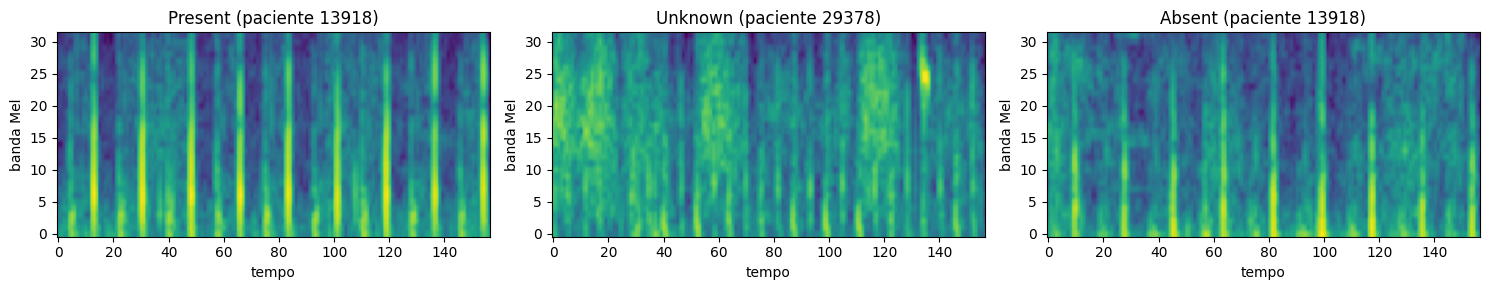

In [16]:
# Verificação visual: um espectrograma de cada classe
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
idx_tr = idx_all
for a, c in zip(ax, CLASSES):
    i = idx_tr.index[idx_tr.y == c][0]
    a.imshow(Xs_all[i].astype(np.float32), origin="lower", aspect="auto")
    a.set_title(f"{c} (paciente {idx_tr.patient_id[i]})"); a.set_xlabel("tempo"); a.set_ylabel("banda Mel")
plt.tight_layout(); plt.show()

### 5.6 Construção dos folds e normalização

Para cada fold, o `make_fold` seleciona as janelas dos pacientes de treino, validação e teste (definidos em 5.1) e normaliza as entradas dos dois modelos:

- **MLP:** `StandardScaler` ajustado às 32 características das janelas de treino.
- **CNN 2D:** média e desvio-padrão globais dos espectrogramas de treino.

As estatísticas vêm **só do treino** e são aplicadas aos três conjuntos, para não haver fuga de informação da validação nem do teste. A saída inclui os metadados de cada janela (`patient_id`, `loc`, `win`, `y`), usados mais tarde para agregar as previsões por paciente.

In [17]:
def make_fold(k, val_size=0.15):
    """Dados do fold k, normalizados com estatísticas calculadas APENAS nos pacientes de treino desse fold."""
    tr_p, va_p, te_p = fold_patients(k, val_size)
    masks = {"train": idx_all.patient_id.isin(tr_p).values,
             "val":   idx_all.patient_id.isin(va_p).values,
             "test":  idx_all.patient_id.isin(te_p).values}

    scaler = StandardScaler().fit(Xf_all[masks["train"]])                      # MLP
    Xs_train = Xs_all[masks["train"]].astype(np.float32)
    mu, sd = Xs_train.mean(), Xs_train.std()                                  # CNN

    out = {}
    for s, m in masks.items():
        out[s] = dict(
            X_mlp=scaler.transform(Xf_all[m]).astype(np.float32),                          # (N, 32)
            X_cnn=((Xs_all[m].astype(np.float32) - mu) / sd)[:, None],                      # (N, 1, 32, T)
            meta=idx_all[m].reset_index(drop=True))                                         # patient_id, loc, win, y
    return out

**Verificação rápida (fold 0):** as formas das entradas, a classe das janelas em cada conjunto e a normalização (no treino a média deve ser ≈ 0 e o desvio-padrão ≈ 1; em validação/teste ficam apenas próximos, porque as estatísticas não foram calculadas com eles).

In [18]:
d0 = make_fold(0)
for s, v in d0.items():
    m = v["meta"]
    print(f"{s:5s} | MLP {v['X_mlp'].shape} | CNN {v['X_cnn'].shape} | {m.patient_id.nunique()} pacientes | janelas por classe: {m.y.value_counts().to_dict()}")

print(f"\nCNN (treino): média {d0['train']['X_cnn'].mean():.3f}, desvio-padrão {d0['train']['X_cnn'].std():.3f}")
print(f"CNN (teste):  média {d0['test']['X_cnn'].mean():.3f}, desvio-padrão {d0['test']['X_cnn'].std():.3f}")
del d0   # liberta memória

train | MLP (16214, 32) | CNN (16214, 1, 32, 157) | 638 pacientes | janelas por classe: {'Absent': 12966, 'Present': 2457, 'Unknown': 791}
val   | MLP (2880, 32) | CNN (2880, 1, 32, 157) | 113 pacientes | janelas por classe: {'Absent': 2230, 'Present': 503, 'Unknown': 147}
test  | MLP (4934, 32) | CNN (4934, 1, 32, 157) | 188 pacientes | janelas por classe: {'Absent': 3993, 'Present': 718, 'Unknown': 223}

CNN (treino): média 0.000, desvio-padrão 1.000
CNN (teste):  média -0.018, desvio-padrão 1.001


---

## 6. Métrica e previsão por paciente

O enunciado exige **uma previsão por paciente** e avalia com a *weighted accuracy* (WA_murmur): é a accuracy em que cada paciente `Present` conta 5 vezes, cada `Unknown` 3 vezes e cada `Absent` 1 vez.

Como a rede classifica **janelas**, é preciso combinar as previsões de todas as janelas (de todas as gravações) de um paciente numa só. O ponto de partida é a **média das probabilidades** das janelas. Atenção: como agora o `Present` só é atribuído às gravações dos focos com sopro, a média sobre todas as janelas do paciente pode **diluir** um sopro presente só num foco. Por isso, na validação, convém comparar a média com alternativas como o **máximo** da probabilidade de `Present` por foco ou o voto maioritário, e justificar a escolha final nos slides.

No fim, `summarize_cv` junta os resultados dos 5 folds: WA média ± desvio-padrão e matriz de confusão agregada (com todos os pacientes).

In [19]:
from sklearn.metrics import confusion_matrix

W = {"Present": 5, "Unknown": 3, "Absent": 1}

def weighted_accuracy(y_true, y_pred):
    """WA_murmur: accuracy com pesos 5/3/1 por classe verdadeira (ao nível do paciente)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    w = np.array([W[t] for t in y_true])
    return (w * (y_true == y_pred)).sum() / w.sum()

def patient_predictions(idx, probs):
    """probs: (N_janelas, 3), colunas na ordem CLASSES. Devolve 1 previsão por paciente (média das probabilidades)."""
    df = pd.DataFrame(probs, columns=CLASSES)
    df["patient_id"] = idx.patient_id.values
    return df.groupby("patient_id")[CLASSES].mean().idxmax(axis=1)

def patient_confusion(y_true, y_pred):
    """Matriz com linhas = previsto e colunas = verdadeiro, como na Tabela 1 do enunciado."""
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=CLASSES).T,
                        index=[f"pred {c}" for c in CLASSES], columns=[f"true {c}" for c in CLASSES])

def summarize_cv(fold_results):
    """fold_results: lista com um (y_true, y_pred) por fold, ao nível do paciente.
    Reporta WA média ± desvio-padrão entre folds e a matriz de confusão agregada de todos os folds."""
    was = [weighted_accuracy(t, p) for t, p in fold_results]
    yt = np.concatenate([np.asarray(t) for t, _ in fold_results])
    yp = np.concatenate([np.asarray(p) for _, p in fold_results])
    print(f"WA_murmur por fold: {np.round(was, 3)}")
    print(f"WA_murmur: {np.mean(was):.3f} ± {np.std(was):.3f}   (agregado: {weighted_accuracy(yt, yp):.3f})")
    print("\nMatriz de confusão agregada (linhas = previsto, colunas = verdadeiro):")
    print(patient_confusion(yt, yp))

# Referência: um classificador que prevê sempre "Absent" (WA baixo apesar de accuracy alta)
y_all = pat["Murmur"].values
print("WA — baseline 'sempre Absent':", round(weighted_accuracy(y_all, ["Absent"] * len(y_all)), 3))

WA — baseline 'sempre Absent': 0.389


O *baseline* "sempre `Absent`" dá WA = 0,389 (694 / (177×5 + 68×3 + 694)): é a referência mínima que qualquer modelo tem de superar. Um modelo que acerte bem só no `Absent` ficará perto deste valor.

---

## 7. Deteção de `Unknown` (MLP)

### 7.1 Objetivo e posição no sistema

Esta secção constrói a **primeira etapa** do sistema: um classificador binário que decide, para cada paciente, se é `Unknown` ou não (`Present`/`Absent`). Só depois se treinam os modelos que distinguem `Present` de `Absent` e se removem as janelas ruidosas. A ordem justifica-se por três razões:

- O `Unknown` corresponde a pacientes cujas gravações não tinham qualidade suficiente para o anotador decidir se havia sopro. É sobretudo um problema de **qualidade do sinal**, e não de reconhecer um padrão de sopro.
- As janelas ruidosas são precisamente o que caracteriza esta classe. Se fossem removidas antes, o modelo perderia o sinal de que precisa para a aprender.
- A literatura segue abordagens semelhantes: Summerton et al. (equipa Murmur Mia!) detetam primeiro os `Unknown`, assumindo que estão ligados a gravações de baixa qualidade, e só depois classificam o sopro; Walker et al. (*Dual Bayesian ResNet*) usam classificadores binários separados e reportam que isso melhora a WA face a um classificador ternário.

### 7.2 Novo dataset com indicadores de qualidade

As 32 características base descrevem o espectro (MFCC, centróide), a intensidade (RMS) e o carácter ruidoso (taxa de passagem por zero), mas não medem diretamente se o sinal tem um ritmo cardíaco reconhecível nem se a energia está espalhada por todas as frequências. Por isso acrescentamos três indicadores de qualidade, definidos para a filtragem de janelas ruidosas e calculados **sem usar labels**:

| Indicador | O que mede | Esperado numa janela de má qualidade |
|---|---|---|
| `hf` | Energia das bandas Mel altas menos a das baixas | valor mais alto (ruído de banda larga) |
| `per` | Pico da autocorrelação da envolvente de energia entre 0,3 e 1,2 s | valor mais baixo (sem ritmo cardíaco claro) |
| `rms_dev` | \|log(RMS)\| (o esperado é RMS ≈ 1, pois o sinal está em z-score) | valor mais alto (picos ou amplitude anómala) |

Ficam **35 características** por janela. Criamos um **novo dataset** (`Xf_unk`, `idx_unk`) e o original (`Xf_all`, `Xs_all`, `idx_all`) fica intacto, porque será usado no modelo `Present`/`Absent` (com a filtragem de janelas ruidosas). Se os indicadores acrescentam informação é verificado com o AUC de cada característica e, mais tarde, com uma ablação (32 contra 35 características).

In [20]:
# Indicadores de qualidade do sinal por janela
FPS = FS / HOP_L                                    # instantes do espectrograma por segundo (31,25)
LAG_MIN, LAG_MAX = int(0.3 * FPS), int(1.2 * FPS)   # duração de um ciclo cardíaco: 0,3–1,2 s
COL_RMS_MEAN = 14                                   # coluna do RMS médio no vetor de 32 características do MLP
QUALITY_COLS = ["hf", "per", "rms_dev"]

def hf_ratio(S):
    """S: (N, N_MELS, T) em dB. Energia média das bandas altas menos a das baixas (alto = ruído de banda larga)."""
    h = S.shape[1] // 2
    return S[:, h:].mean(axis=(1, 2)) - S[:, :h].mean(axis=(1, 2))

def periodicity(S):
    """Pico da autocorrelação da envolvente de energia na gama de um ciclo cardíaco (baixo = sem ritmo cardíaco claro)."""
    env = S.mean(axis=1)
    env = env - env.mean(axis=1, keepdims=True)
    n = env.shape[1]
    f = np.fft.rfft(env, n=2 * n, axis=1)
    ac = np.fft.irfft(f * np.conj(f), axis=1)[:, :n]
    ac = ac / (ac[:, :1] + 1e-8)
    return ac[:, LAG_MIN:LAG_MAX + 1].max(axis=1)

def quality_metrics(Xs, Xf, batch=2000):
    """DataFrame (N, 3) com hf, per e rms_dev de cada janela, pela mesma ordem de Xs/Xf."""
    hf, per = [], []
    for i in range(0, len(Xs), batch):                       # em lotes, para não converter tudo para float32 de uma vez
        S = Xs[i:i + batch].astype(np.float32)
        hf.append(hf_ratio(S)); per.append(periodicity(S))
    return pd.DataFrame({"hf": np.concatenate(hf),
                         "per": np.concatenate(per),
                         "rms_dev": np.abs(np.log(Xf[:, COL_RMS_MEAN] + 1e-8))})   # |log(RMS)|: o esperado é ~1 (z-score)

In [21]:
# Novo dataset para o modelo de Unknown: 32 características base + 3 de qualidade
Xf_base, Xs_base, idx_base = data_all            # versão completa vinda da cache (independente de qualquer filtragem posterior)

Q = quality_metrics(Xs_base, Xf_base)
Xf_unk = np.hstack([Xf_base, Q.values.astype(np.float32)])                  # (N, 35)

FEATURES_BASE = ([f"mfcc{i}_mean" for i in range(13)] + ["centroid_mean", "rms_mean", "zcr_mean"] +
                 [f"mfcc{i}_std" for i in range(13)] + ["centroid_std", "rms_std", "zcr_std"])
FEATURES_UNK = FEATURES_BASE + QUALITY_COLS
assert Xf_unk.shape[1] == len(FEATURES_UNK)

# Label binária ao nível do paciente: 1 = Unknown, 0 = Present/Absent
y_pat = pat.set_index("patient_id")["Murmur"]
idx_unk = idx_base.copy()
idx_unk["y_unk"] = (idx_unk.patient_id.map(y_pat) == "Unknown").astype(int)
assert (idx_unk.y_unk == (idx_unk.y == "Unknown")).all()                    # coerente com as labels por gravação

n_unk_pac = idx_unk.loc[idx_unk.y_unk == 1, "patient_id"].nunique()
print(f"Dataset original (inalterado): {Xf_all.shape} | dataset Unknown: {Xf_unk.shape}")
print(f"Janelas Unknown: {idx_unk.y_unk.sum()} de {len(idx_unk)} ({100 * idx_unk.y_unk.mean():.1f}%) | pacientes Unknown: {n_unk_pac}")
print("\nMédia dos indicadores de qualidade (0 = resto, 1 = Unknown):")
print(Q.groupby(idx_unk.y_unk.values).mean().round(3))

Dataset original (inalterado): (24028, 32) | dataset Unknown: (24028, 35)
Janelas Unknown: 1161 de 24028 (4.8%) | pacientes Unknown: 68

Média dos indicadores de qualidade (0 = resto, 1 = Unknown):
      hf    per  rms_dev
0 -8.941  0.351    0.564
1 -5.893  0.275    0.634


Para perceber se os três novos indicadores são realmente úteis na identificação dos `Unknown`, calculamos o **ROC AUC** de cada característica do dataset (as 32 originais e as 3 novas), usada isoladamente como pontuação para separar as janelas `Unknown` das restantes. Um AUC de 0,5 indica que a característica não separa as classes; quanto mais afastado de 0,5 (acima ou abaixo), maior a separação. Os histogramas mostram a distribuição de cada indicador nos dois grupos.

Top 10 características por separação (AUC; 0,5 = sem separação; AUC < 0,5 = valores mais baixos no Unknown;
* = indicador de qualidade novo):
  mfcc1_mean      AUC = 0.237 
  centroid_mean   AUC = 0.762 
  hf              AUC = 0.758 *
  zcr_mean        AUC = 0.740 
  zcr_std         AUC = 0.664 
  mfcc2_mean      AUC = 0.362 
  per             AUC = 0.368 *
  mfcc3_mean      AUC = 0.370 
  mfcc8_mean      AUC = 0.405 
  centroid_std    AUC = 0.591 


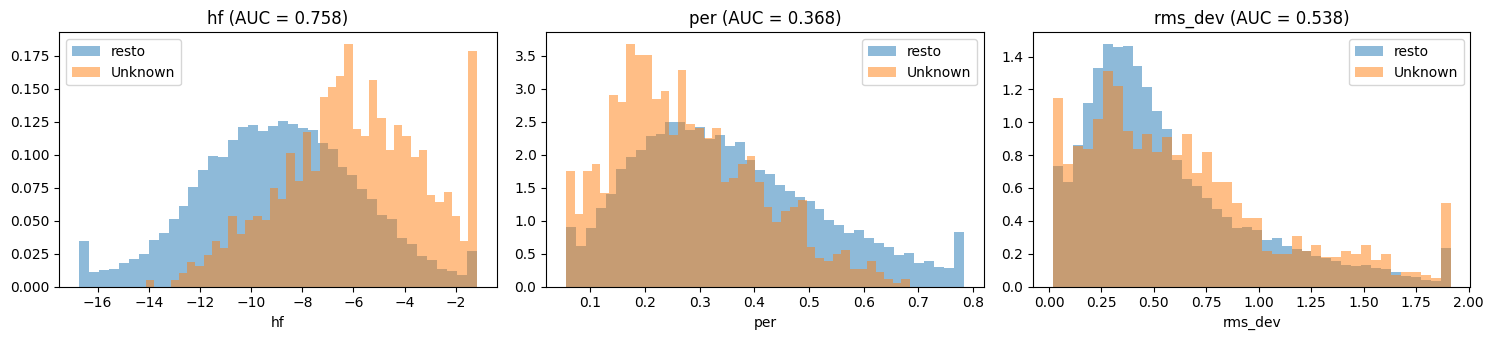

In [22]:
auc_uni = pd.Series({f: roc_auc_score(idx_unk.y_unk, Xf_unk[:, j]) for j, f in enumerate(FEATURES_UNK)})
top = (auc_uni - 0.5).abs().sort_values(ascending=False).head(10).index
print("Top 10 características por separação (AUC; 0,5 = sem separação; AUC < 0,5 = valores mais baixos no Unknown;")
print("* = indicador de qualidade novo):")
for f in top:
    print(f"  {f:15s} AUC = {auc_uni[f]:.3f} {'*' if f in QUALITY_COLS else ''}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, QUALITY_COLS):
    lo, hi = Q[c].quantile([0.01, 0.99])
    for lab, nome in [(0, "resto"), (1, "Unknown")]:
        a.hist(Q.loc[idx_unk.y_unk.values == lab, c].clip(lo, hi), bins=40, density=True, alpha=0.5, label=nome)
    a.set_title(f"{c} (AUC = {auc_uni[c]:.3f})"); a.set_xlabel(c); a.legend()
plt.tight_layout(); plt.show()

**Resultados:** `hf` (AUC = 0.758) e `per` (AUC = 0.368) são bastante úteis e ajudam a identificar os `Unknown`. Já o `rms_dev` (AUC = 0.538) é menos útil, porque os seus valores nos `Unknown` são muito semelhantes aos das restantes janelas.

**Ressalva:**
- Este AUC avalia cada característica **isoladamente** e ao nível da **janela**, enquanto o MLP combina todas. Uma característica fraca sozinha pode ainda ajudar em conjunto.

### 7.3 Folds e normalização

Reutilizamos `fold_patients` (secção 5.1), logo os pacientes de treino, validação e teste de cada fold são os mesmos que no resto do trabalho, o que torna os resultados comparáveis. A normalização (`StandardScaler`) é ajustada só ao treino de cada fold.

In [23]:
def make_fold_unk(k, val_size=0.15):
    """MLP/Unknown: dados do fold k (mesmos folds de pacientes do resto do trabalho), normalizados só com o treino."""
    tr_p, va_p, te_p = fold_patients(k, val_size)
    masks = {"train": idx_unk.patient_id.isin(tr_p).values,
             "val":   idx_unk.patient_id.isin(va_p).values,
             "test":  idx_unk.patient_id.isin(te_p).values}
    scaler = StandardScaler().fit(Xf_unk[masks["train"]])
    return {s: dict(X=scaler.transform(Xf_unk[m]).astype(np.float32),                  # (N, 35)
                    y=idx_unk.y_unk.values[m].astype(np.float32),                      # 0/1 por janela
                    meta=idx_unk[m].reset_index(drop=True))                            # patient_id, loc, win, y, y_unk
            for s, m in masks.items()}

### 7.4 Porquê um MLP e o que esperar

**Porquê um MLP:**
1. **A qualidade é uma propriedade global da janela**, bem resumida por poucos números (ritmo, balanço de frequências, amplitude). Um vetor de características é a entrada natural; uma CNN teria de aprender estes indicadores a partir do espectrograma.
2. **Há poucos dados na classe:** 68 pacientes (≈ 5% das janelas). Um MLP pequeno tem poucos parâmetros (≈ 4 mil) e sobreajusta menos do que uma CNN.
3. **Treina em segundos**, o que permite afinar hiperparâmetros e repetir com várias sementes, importante numa classe rara em que os resultados variam muito entre folds.
4. Na literatura, a etapa de deteção de `Unknown` da Murmur Mia! usa características globais das gravações (com *gradient boosting*), o que apoia esta escolha.

**O que esperar:** o `Unknown` é uma classe difícil e, em geral, o desempenho nela é fraco, mesmo nos melhores sistemas. A abordagem de Cambridge baseada num limiar de qualidade da segmentação (HSMM paralelos) obteve cerca de 31% de sensibilidade e 34% de PPV no `Unknown`. Os autores do algoritmo vencedor do desafio reconhecem o mau desempenho nesta classe e notam que a noção de "sinal de má qualidade" para um algoritmo e para um humano é provavelmente muito diferente. **Não se espera, por isso, um desempenho elevado:** o objetivo é superar o acaso (AUC 0,5; AP igual à prevalência, ≈ 0,07) e referências simples, e analisar o que o modelo consegue captar.

### 7.5 MLP base: arquitetura e treino

Esta é a **configuração inicial**; os valores serão testados e ajustados na validação (secção 7.7).

| Componente | Valor base | Justificação |
|---|---|---|
| Entrada | 35 características, padronizadas com o treino | Mesma entrada do MLP, mais os 3 indicadores de qualidade |
| Camadas | 2 ocultas (64 → 32 neurónios) + 1 neurónio de saída | Rede pequena (≈ 4,4 mil parâmetros) para poucos dados; o estreitamento força um resumo compacto |
| Ativação | ReLU nas ocultas; sigmoide na saída (incluída na *loss*) | ReLU é o padrão, treina depressa e evita saturação; a saída é a probabilidade de `Unknown` |
| *Loss* | *Binary cross-entropy* com `pos_weight` = n.º de negativos / n.º de positivos (≈ 20) | O `Unknown` é ≈ 5% das janelas; o peso faz com que os erros nesta classe contem tanto como os da outra |
| Otimizador | Adam, taxa de aprendizagem 1e-3 | Adam adapta o passo por parâmetro e é robusto a escalas diferentes das características |
| *Mini-batch* | 256 janelas | Compromisso entre ruído do gradiente e velocidade |
| Épocas | máx. 100, com *early stopping* (paciência 10, pela AP na validação, restaura os melhores pesos) | O número de épocas é decidido pela validação |
| Regularização | *Dropout* 0,3; *weight decay* 1e-4; *early stopping* | Evitam sobreajuste, sobretudo com poucos pacientes `Unknown` |

In [24]:
# Configuração base (ponto de partida; os valores serão testados na secção 7.7)
CFG_UNK = dict(hidden=(64, 32), dropout=0.3, lr=1e-3, weight_decay=1e-4,
               batch_size=256, max_epochs=100, patience=10, seed=SEED)

def build_mlp(n_in, hidden=(64, 32), dropout=0.3):
    """MLP: [Linear -> ReLU -> Dropout] x len(hidden) -> Linear(1). A saída é um logit (a sigmoide está na loss)."""
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)

@torch.no_grad()
def predict_proba(model, X):
    """Probabilidade de Unknown para cada janela."""
    model.eval()
    return torch.sigmoid(model(torch.from_numpy(X)).squeeze(1)).numpy()

def train_unk(data, cfg=CFG_UNK):
    """Treina o MLP num fold. Early stopping pela AP (average precision) na validação; devolve o modelo com os melhores pesos."""
    torch.manual_seed(cfg["seed"])
    Xtr, ytr = torch.from_numpy(data["train"]["X"]), torch.from_numpy(data["train"]["y"])
    Xva, yva = torch.from_numpy(data["val"]["X"]), torch.from_numpy(data["val"]["y"])

    n_pos = ytr.sum().item(); n_neg = len(ytr) - n_pos
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos]))     # desequilíbrio: pesa os positivos (Unknown)

    model = build_mlp(Xtr.shape[1], cfg["hidden"], cfg["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=cfg["batch_size"], shuffle=True,
                        generator=torch.Generator().manual_seed(cfg["seed"]))

    hist, best_ap, best_ep = [], -1.0, 0
    best_state = {k: v.clone() for k, v in model.state_dict().items()}      # garante que existe sempre um estado a restaurar
    for ep in range(1, cfg["max_epochs"] + 1):
        model.train(); tot = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb).squeeze(1), yb)
            loss.backward(); opt.step()
            tot += loss.item() * len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva).squeeze(1), yva).item()
        ap = average_precision_score(data["val"]["y"], predict_proba(model, data["val"]["X"]))
        hist.append(dict(epoch=ep, train_loss=tot / len(Xtr), val_loss=val_loss, val_ap_win=ap))

        if ap > best_ap:
            best_ap, best_ep = ap, ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        elif ep - best_ep >= cfg["patience"]:                 # early stopping
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep

_m = build_mlp(len(FEATURES_UNK), CFG_UNK["hidden"], CFG_UNK["dropout"])
print(_m)
print("Parâmetros treináveis:", sum(p.numel() for p in _m.parameters()))

Sequential(
  (0): Linear(in_features=35, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Parâmetros treináveis: 4417


### 7.6 Como se decide se um paciente é `Unknown` e como se avalia

**Da janela à decisão do paciente:**

1. **Janela → probabilidade.** O MLP recebe as 35 características de **uma janela** e devolve um valor entre 0 e 1 (a sigmoide do logit), que indica o quão parecida com um `Unknown` é essa janela. Cada janela é avaliada isoladamente; o modelo nunca vê o paciente como um todo.
2. **Janelas → paciente.** A pontuação do paciente é a **média** das probabilidades de todas as suas janelas (de todas as gravações e focos).
3. **Pontuação → decisão.** Se a pontuação for **maior ou igual a um limiar**, o paciente é classificado como `Unknown`.
4. **Escolha do limiar.** O limiar não é fixo em 0,5: em cada fold, é escolhido nos pacientes de **validação** (o valor que maximiza a WA 5-1) e aplicado, sem alterações, aos pacientes de **teste**.

**Métricas** (por paciente, no teste):
- **Weighted accuracy (WA 5-1):** (5·TP + 1·TN) / (5·P + 1·N). Acertar num `Unknown` vale 5 e acertar num paciente não-`Unknown` vale 1. Os pesos estão em `W_UNK` e `W_REST` (o desafio PhysioNet usa 3 para `Unknown`). Nunca prever `Unknown` já dá uma WA ≈ 0,72, que é a referência a superar.
- **F1 da classe `Unknown`:** média harmónica da precisão e do *recall*; ignora os verdadeiros negativos, por isso reflete o desempenho na classe rara.
- **ROC AUC:** probabilidade de um paciente `Unknown` ter pontuação mais alta do que um não-`Unknown`; não depende do limiar (0,5 = acaso).
- **Matriz de confusão**, agregada nos 5 folds (cada paciente aparece uma vez no teste).

*Notas:* a WA e o F1 dependem do limiar, o AUC não, por isso o AUC de validação é a métrica mais fiável para comparar hiperparâmetros. A validação é usada duas vezes (*early stopping* e escolha do limiar), logo as métricas de validação são otimistas; o teste serve apenas para reportar.

In [25]:
W_UNK, W_REST = 5, 1        # pesos da weighted accuracy: cada paciente Unknown conta 5, cada paciente não-Unknown conta 1

def weighted_accuracy(y, pred, w_pos=W_UNK, w_neg=W_REST):
    """WA = (w_pos·TP + w_neg·TN) / (w_pos·P + w_neg·N), com 1 = Unknown."""
    y, pred = np.asarray(y), np.asarray(pred)
    tp = ((pred == 1) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
    return (w_pos * tp + w_neg * tn) / (w_pos * (y == 1).sum() + w_neg * (y == 0).sum())

def patient_scores(meta, probs):
    """Pontuação do paciente = média das probabilidades de Unknown de todas as suas janelas."""
    return pd.Series(probs, index=meta.patient_id.values).groupby(level=0).mean()

def eval_patient(data, model, split):
    """Devolve (pontuação por paciente, label por paciente) para o conjunto 'val' ou 'test'."""
    meta = data[split]["meta"]
    s = patient_scores(meta, predict_proba(model, data[split]["X"]))
    y = meta.groupby("patient_id")["y_unk"].max().reindex(s.index)
    return s, y

def best_threshold(y, s, metric="wa"):
    """Limiar que maximiza a WA 5-1 (ou o F1) nos pacientes de VALIDAÇÃO. Em caso de empate, usa o limiar do meio."""
    y, cand = np.asarray(y), np.unique(s.values)
    score = (lambda p: weighted_accuracy(y, p)) if metric == "wa" else (lambda p: f1_score(y, p, zero_division=0))
    vals = np.array([score((s.values >= t).astype(int)) for t in cand])
    best = np.flatnonzero(np.isclose(vals, vals.max()))
    return cand[best[len(best) // 2]]

def plot_confusion(y, pred, title="Matriz de confusão (pacientes de teste, 5 folds)"):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)
    nomes = ["não-Unknown", "Unknown"]
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    ax.imshow(pct, vmin=0, vmax=1, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * pct[i, j]:.0f}%)", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(nomes); ax.set_yticks([0, 1]); ax.set_yticklabels(nomes)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.show()

def run_cv_unk(cfg=CFG_UNK, folds=range(N_FOLDS), thr_metric="wa"):
    """Treina e avalia nos folds. Métricas ao nível do PACIENTE; limiar escolhido na validação de cada fold."""
    rows, hists, ys, ps, ss = [], {}, [], [], []
    for k in folds:
        d = make_fold_unk(k)
        model, hist, best_ep = train_unk(d, cfg)
        hists[k] = hist
        s_va, y_va = eval_patient(d, model, "val")
        s_te, y_te = eval_patient(d, model, "test")
        thr = best_threshold(y_va, s_va, thr_metric)              # escolhido na validação...
        pred = (s_te.values >= thr).astype(int)                    # ...e aplicado ao teste
        tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
        rows.append(dict(fold=k, best_epoch=best_ep, thr=thr, val_auc=roc_auc_score(y_va, s_va),
                         test_auc=roc_auc_score(y_te, s_te), test_wa=weighted_accuracy(y_te, pred),
                         test_f1=f1_score(y_te, pred, zero_division=0), tp=tp, fp=fp, fn=fn, tn=tn))
        ys.append(y_te.values); ps.append(pred); ss.append(s_te.values)

    res = pd.DataFrame(rows).set_index("fold")
    y_all, p_all, s_all = np.concatenate(ys), np.concatenate(ps), np.concatenate(ss)
    n_pos = int(y_all.sum()); n_neg = len(y_all) - n_pos
    tot = W_UNK * n_pos + W_REST * n_neg

    print(res.round(3).to_string())
    ms = lambda c: f"{res[c].mean():.3f} ± {res[c].std():.3f}"
    print(f"\nValidação (média ± dp dos folds): AUC {ms('val_auc')}")
    print(f"Teste (média ± dp dos folds):     WA {ms('test_wa')} | F1 {ms('test_f1')} | AUC {ms('test_auc')}")
    print(f"Teste (agregado, {len(y_all)} pacientes):  WA {weighted_accuracy(y_all, p_all):.3f} | F1 {f1_score(y_all, p_all, zero_division=0):.3f} "
          f"| AUC {roc_auc_score(y_all, s_all):.3f}")
    print(f"\nReferências: nunca prever Unknown -> WA {W_REST * n_neg / tot:.3f}, F1 0,000 | "
          f"prever sempre Unknown -> WA {W_UNK * n_pos / tot:.3f}, F1 {2 * n_pos / (2 * n_pos + n_neg):.3f} | acaso -> AUC 0,500")
    return res, hists, dict(y=y_all, pred=p_all, score=s_all)

      best_epoch    thr  val_auc  test_auc  test_wa  test_f1  tp  fp  fn   tn
fold                                                                         
0              3  0.641    0.804     0.778    0.833    0.444   8  15   5  160
1              2  0.593    0.930     0.719    0.713    0.211   4  20  10  154
2              9  0.560    0.864     0.753    0.766    0.326   7  22   7  152
3              1  0.742    0.693     0.888    0.762    0.300   3   3  11  171
4             10  0.577    0.848     0.806    0.745    0.281   8  36   5  138

Validação (média ± dp dos folds): AUC 0.828 ± 0.088
Teste (média ± dp dos folds):     WA 0.764 ± 0.044 | F1 0.312 ± 0.085 | AUC 0.789 ± 0.064
Teste (agregado, 939 pacientes):  WA 0.764 | F1 0.309 | AUC 0.782

Referências: nunca prever Unknown -> WA 0.719, F1 0,000 | prever sempre Unknown -> WA 0.281, F1 0.135 | acaso -> AUC 0,500


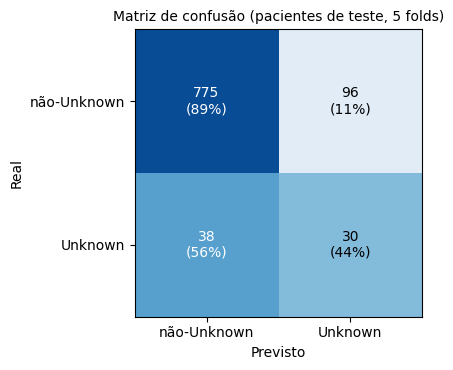

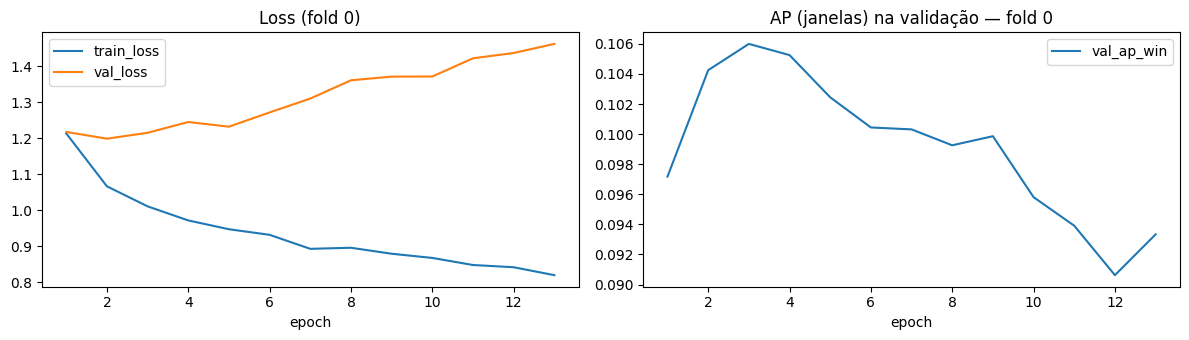

In [26]:
res_base, hists_base, pooled_base = run_cv_unk(CFG_UNK)
plot_confusion(pooled_base["y"], pooled_base["pred"])

# Curvas de aprendizagem do fold 0
h = hists_base[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
h.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss (fold 0)")
h.plot(x="epoch", y="val_ap_win", ax=ax[1], title="AP (janelas) na validação — fold 0")
plt.tight_layout(); plt.show()

**Análise dos resultados da versão base** (É PRECISO LER ISTO TUDO E DEIXAR SO O QUE QUERO MAS FAÇO DEPOIS)

- **O modelo aprende algum sinal, mas o ganho é modesto.** O AUC agregado é 0,78 (intervalo de confiança a 95% de ≈ 0,72–0,85, aproximado), claramente acima do acaso (0,5), o que mostra que as características contêm informação sobre o `Unknown`. A WA 5-1 é 0,764, contra 0,719 de nunca prever `Unknown` (+0,045), e o F1 é 0,31 (0,135 se se previsse sempre `Unknown`).

- **Compromisso da matriz de confusão.** O modelo apanha 44% dos `Unknown` (30 em 68) e classifica bem 89% dos restantes (775 em 871), mas só 24% dos pacientes que assinala são mesmo `Unknown` (30 em 126). Prevê `Unknown` para 13% dos pacientes, quando a prevalência real é 7%. É o esperado com pesos 5-1: cada `Unknown` encontrado vale 5 falsos alarmes, logo compensa assinalar mais pacientes desde que a precisão fique acima de 1/6 (≈ 17%), o que acontece (24%).

- **Grande variabilidade entre folds.** No teste, a WA varia entre 0,713 e 0,833, o F1 entre 0,21 e 0,44 e o AUC entre 0,72 e 0,89. Cada fold de teste tem só 13–14 `Unknown`, pelo que um paciente a mais ou a menos altera o *recall* em ≈ 7 pontos percentuais (o IC a 95% do *recall* agregado é ≈ 33–56%). O AUC de validação e o de teste também não coincidem (fold 1: 0,93 e 0,72), por haver só ≈ 8 `Unknown` por validação. As conclusões devem, por isso, ser prudentes.

- **Sobreajuste rápido (curvas do fold 0).** A *loss* de treino desce sempre, mas a de validação sobe a partir da época 2, e a AP das janelas atinge o máximo na época 3 (≈ 0,106) e depois desce. A melhor época dos folds fica entre 1 e 10, o que indica que o modelo aprende depressa o pouco sinal útil e depois memoriza o ruído do treino. A AP por janela é baixa (cerca do dobro da prevalência de janelas `Unknown`, ≈ 5%) e quase plana, pelo que a época escolhida pelo *early stopping* é em parte devida ao acaso. Ainda assim, ao nível do paciente o AUC chega a ≈ 0,8, porque a média das probabilidades de várias janelas reduz o ruído das labels (todas as janelas de um paciente `Unknown` têm label 1, mesmo as de boa qualidade).

**Conclusão e próximos passos:** a versão base aprende um sinal real, mas sobreajusta depressa e é instável. As experiências seguintes (secção 7.7) devem testar se os 3 indicadores de qualidade ajudam (ablação), mais regularização ou uma rede mais pequena para travar o sobreajuste, e o critério do *early stopping* (por exemplo, a *loss* de validação ou o AUC por paciente em vez da AP das janelas). Devem repetir-se com várias sementes, dada a variabilidade.

In [27]:
Xf_raw, Xs_raw, idx_raw = data_all

---

## 7.7. Anexo A — Filtragem de janelas ruidosas (desativada)

> **Estado: desativada.** Decidimos construir primeiro o modelo para `Unknown` e só depois remover janelas ruidosas. As duas células seguintes estão "comentadas" (entre aspas triplas `'''`): para as ativar, retirar as aspas do início e do fim de cada uma. Têm de ser executadas **antes** de chamar `make_fold`, porque substituem `Xf_all`, `Xs_all` e `idx_all`.

Algumas janelas não permitem identificar o ciclo cardíaco nem um possível sopro (ruído de movimento, fricção do estetoscópio, ruído ambiente). Manter estas janelas com a label da gravação acrescenta ruído às labels. Por isso, sinalizamos as janelas de pior qualidade com três critérios que **não usam as labels**:

| Critério | O que mede | Sinal de má qualidade |
|---|---|---|
| `hf` | Energia média das bandas Mel altas menos a das baixas | Valor alto: ruído de banda larga (os sons cardíacos concentram-se em baixas frequências) |
| `per` | Pico da autocorrelação da envolvente de energia entre 0,3 e 1,2 s | Valor baixo: não se vê um ritmo cardíaco regular |
| `rms_dev` | \|log(RMS)\| da janela (o sinal está em z-score, logo o esperado é RMS ≈ 1) | Valor alto: picos ou artefactos de amplitude |

Uma janela é removida se falhar **em pelo menos um** dos critérios. Os limiares são **percentis** calculados sobre todas as janelas (por defeito 10% / 10% / 3%), sem usar labels; são valores iniciais a ajustar na validação.

**Pacientes sem janelas → `Unknown` automático.** Se todas as janelas de um paciente forem ruidosas (parâmetro `UNK_FRAC`), o paciente é dado como `Unknown`: a previsão fica fixa e as suas janelas não entram no treino. O código imprime a **precisão** (que fração desses pacientes são mesmo `Unknown`) e a **cobertura** (que fração dos `Unknown` é apanhada) para avaliar se a regra se justifica. Ideia semelhante existe na literatura: *Heart Murmur and Abnormal PCG Detection via Wavelet Scattering Transform & a 1D-CNN* (arXiv 2303.11423) re-etiqueta como `Unknown` os segmentos do CirCor que só contêm ruído.

In [28]:

# Fração de janelas sinalizada por cada critério
Q_HF, Q_PER, Q_RMS = 0.10, 0.10, 0.03

# Métricas de qualidade de todas as janelas
Q_raw = quality_metrics(Xs_raw, Xf_raw)

q = idx_raw[["patient_id", "loc", "win", "y"]].copy()
q["hf"] = Q_raw["hf"].values
q["per"] = Q_raw["per"].values
q["rms_dev"] = Q_raw["rms_dev"].values

# Identificar janelas ruidosas
q["bad_hf"] = q.hf > q.hf.quantile(1 - Q_HF)
q["bad_per"] = q.per < q.per.quantile(Q_PER)
q["bad_rms"] = q.rms_dev > q.rms_dev.quantile(1 - Q_RMS)

q["noisy"] = q[["bad_hf", "bad_per", "bad_rms"]].any(axis=1)

# Selecionar apenas janelas Present/Absent que não sejam ruidosas
keep_pa = q["y"].isin(["Present", "Absent"]) & ~q["noisy"]

Xf_pa = Xf_raw[keep_pa.values]
Xs_pa = Xs_raw[keep_pa.values]
idx_pa = idx_raw.loc[keep_pa].reset_index(drop=True)

# Resumo
res = pd.DataFrame({
    "antes": idx_raw[idx_raw.y.isin(["Present", "Absent"])].y.value_counts(),
    "depois": idx_pa.y.value_counts()
}).reindex(["Present", "Absent"])

res["removidas (%)"] = (100 * (1 - res.depois / res.antes)).round(1)

print(f"Janelas Present/Absent: {keep_pa.sum()} mantidas")
print(f"Janelas removidas: {(~keep_pa & q.y.isin(['Present', 'Absent'])).sum()}")
print("\nResumo por classe:")
print(res)

print("\nJanelas sinalizadas por critério (%), por classe:")
print(
    (100 * q.groupby("y")[["bad_hf", "bad_per", "bad_rms", "noisy"]]
     .mean()).round(1)
)

print("\nJanelas removidas (%) por foco:")
print(
    (100 * (1 - q.loc[q.y.isin(["Present", "Absent"])]
            .groupby("loc")["noisy"].apply(lambda x: 1 - x.mean()))).round(1)
)


Janelas Present/Absent: 18430 mantidas
Janelas removidas: 4437

Resumo por classe:
         antes  depois  removidas (%)
y                                    
Present   3678    3201           13.0
Absent   19189   15229           20.6

Janelas sinalizadas por critério (%), por classe:
         bad_hf  bad_per  bad_rms  noisy
y                                       
Absent      9.2     10.3      3.3   20.6
Present     7.2      6.2      0.8   13.0
Unknown    32.4     17.0      4.9   47.0

Janelas removidas (%) por foco:
loc
AV    29.3
MV    19.6
PV    15.9
TV    12.4
Name: noisy, dtype: float64


In [31]:
'''# Exemplos de janelas removidas (uma linha por critério) vs. janelas mantidas, na mesma escala de cor
rng = np.random.default_rng(SEED)
linhas = [("bad_hf",  "hf",      "Ruído de banda larga"),
          ("bad_per", "per",     "Sem periodicidade cardíaca"),
          ("bad_rms", "rms_dev", "Amplitude anómala"),
          (None,      None,      "Mantida")]
vmin, vmax = np.percentile(Xs_raw[::50].astype(np.float32), [1, 99])

fig, ax = plt.subplots(len(linhas), 3, figsize=(15, 3 * len(linhas)))
for r, (flag, met, nome) in enumerate(linhas):
    pool = q.index[~q.keep & q[flag]] if flag else q.index[q.keep]
    for c, i in enumerate(rng.choice(pool, size=min(3, len(pool)), replace=False)):
        a = ax[r, c]
        a.imshow(Xs_raw[i].astype(np.float32), origin="lower", aspect="auto", vmin=vmin, vmax=vmax)
        val = f" — {met}={q.loc[i, met]:.2f}" if met else ""
        a.set_title(f"{nome}\n{q.y[i]} (paciente {q.patient_id[i]}, {q['loc'][i]}){val}", fontsize=9)
        if c == 0: a.set_ylabel("banda Mel")
        if r == len(linhas) - 1: a.set_xlabel("tempo")
plt.tight_layout(); plt.show()'''

'# Exemplos de janelas removidas (uma linha por critério) vs. janelas mantidas, na mesma escala de cor\nrng = np.random.default_rng(SEED)\nlinhas = [("bad_hf",  "hf",      "Ruído de banda larga"),\n          ("bad_per", "per",     "Sem periodicidade cardíaca"),\n          ("bad_rms", "rms_dev", "Amplitude anómala"),\n          (None,      None,      "Mantida")]\nvmin, vmax = np.percentile(Xs_raw[::50].astype(np.float32), [1, 99])\n\nfig, ax = plt.subplots(len(linhas), 3, figsize=(15, 3 * len(linhas)))\nfor r, (flag, met, nome) in enumerate(linhas):\n    pool = q.index[~q.keep & q[flag]] if flag else q.index[q.keep]\n    for c, i in enumerate(rng.choice(pool, size=min(3, len(pool)), replace=False)):\n        a = ax[r, c]\n        a.imshow(Xs_raw[i].astype(np.float32), origin="lower", aspect="auto", vmin=vmin, vmax=vmax)\n        val = f" — {met}={q.loc[i, met]:.2f}" if met else ""\n        a.set_title(f"{nome}\n{q.y[i]} (paciente {q.patient_id[i]}, {q[\'loc\'][i]}){val}", fontsize=9)\n 

### 7.4. Preparação dos dados para os modelos Present/Absent

Após a filtragem de ruído, preparamos os dados para os modelos MLP e CNN2D.

A função `make_fold_pa()` utiliza os cinco folds definidos anteriormente, mantendo a separação dos dados ao nível do paciente.

Em cada fold:
- São selecionadas as janelas limpas dos conjuntos de treino, validação e teste.
- As características da MLP são normalizadas com um `StandardScaler` ajustado apenas aos dados de treino.
- Os espectrogramas da CNN2D são normalizados utilizando a média e o desvio-padrão calculados apenas no treino.

Desta forma, ambos os modelos utilizam a mesma divisão dos dados, evitando fuga de informação entre os conjuntos.

In [32]:

def make_fold_pa(k, val_size=0.15):
    """Dados do fold k para Present/Absent, usando apenas janelas limpas."""

    tr_p, va_p, te_p = fold_patients(k, val_size)

    masks = {
        "train": idx_pa.patient_id.isin(tr_p).values,
        "val":   idx_pa.patient_id.isin(va_p).values,
        "test":  idx_pa.patient_id.isin(te_p).values
    }

    # MLP: normalização ajustada apenas com as janelas de treino
    scaler = StandardScaler().fit(Xf_pa[masks["train"]])

    # CNN: média e desvio-padrão calculados apenas no treino
    Xs_train = Xs_pa[masks["train"]].astype(np.float32)
    mu, sd = Xs_train.mean(), Xs_train.std()

    out = {}

    for s, m in masks.items():
        out[s] = dict(
            X_mlp=scaler.transform(Xf_pa[m]).astype(np.float32),
            X_cnn=((Xs_pa[m].astype(np.float32) - mu) / sd)[:, None],
            meta=idx_pa[m].reset_index(drop=True)
        )

    return out


In [33]:

d0_pa = make_fold_pa(0)

for s, v in d0_pa.items():
    m = v["meta"]

    print(
        f"{s:5s} | "
        f"MLP {v['X_mlp'].shape} | "
        f"CNN {v['X_cnn'].shape} | "
        f"{m.patient_id.nunique()} pacientes | "
        f"janelas por classe: {m.y.value_counts().to_dict()}"
    )

    assert set(m.y.unique()).issubset({"Present", "Absent"})

print("\nCNN (treino):")
print(f"Média: {d0_pa['train']['X_cnn'].mean():.3f}")
print(f"Desvio-padrão: {d0_pa['train']['X_cnn'].std():.3f}")

del d0_pa


train | MLP (12449, 32) | CNN (12449, 1, 32, 157) | 587 pacientes | janelas por classe: {'Absent': 10314, 'Present': 2135}
val   | MLP (2199, 32) | CNN (2199, 1, 32, 157) | 104 pacientes | janelas por classe: {'Absent': 1742, 'Present': 457}
test  | MLP (3782, 32) | CNN (3782, 1, 32, 157) | 174 pacientes | janelas por classe: {'Absent': 3173, 'Present': 609}

CNN (treino):
Média: 0.000
Desvio-padrão: 1.000


### 7.5. Identificação e exclusão de pacientes sem janelas limpas

Após a filtragem de ruído, alguns pacientes podem ficar sem janelas disponíveis, caso todas as suas janelas tenham sido identificadas como ruidosas.

Estes pacientes são identificados através da comparação entre os pacientes originalmente classificados como `Present` ou `Absent` e os pacientes que continuam representados no conjunto filtrado.

Os pacientes sem janelas limpas são excluídos dos modelos finais, uma vez que não existem dados que permitam obter previsões para esses casos.

Os dados originais são preservados e os IDs dos pacientes excluídos são guardados para documentação.

In [37]:

pacientes_pa = set(
    pat.loc[pat.Murmur.isin(["Present", "Absent"]), "patient_id"]
)

pacientes_com_janelas = set(idx_pa.patient_id.unique())

pacientes_sem_janelas = sorted(pacientes_pa - pacientes_com_janelas)

print("Pacientes Present/Absent:", len(pacientes_pa))
print("Pacientes com janelas limpas:", len(pacientes_pa & pacientes_com_janelas))
print("Pacientes sem janelas limpas:", len(pacientes_sem_janelas))
print("IDs dos pacientes excluídos:", pacientes_sem_janelas)


Pacientes Present/Absent: 871
Pacientes com janelas limpas: 865
Pacientes sem janelas limpas: 6
IDs dos pacientes excluídos: [46778, 51064, 68269, 84688, 84784, 85063]


In [38]:

exclusao_pacientes = pd.DataFrame({
    "patient_id": pacientes_sem_janelas,
    "motivo": "Sem janelas limpas após filtragem de ruído"
})

print(exclusao_pacientes)


   patient_id                                      motivo
0       46778  Sem janelas limpas após filtragem de ruído
1       51064  Sem janelas limpas após filtragem de ruído
2       68269  Sem janelas limpas após filtragem de ruído
3       84688  Sem janelas limpas após filtragem de ruído
4       84784  Sem janelas limpas após filtragem de ruído
5       85063  Sem janelas limpas após filtragem de ruído


### 7.6. Validação da estratégia de 5-fold cross-validation

Antes do treino dos modelos, verificamos a distribuição dos pacientes pelos cinco folds.

A validação garante que:
- Todos os pacientes com janelas limpas são avaliados;
- Cada paciente aparece exatamente uma vez como teste;
- Não existem pacientes repetidos nos conjuntos de teste;
- Nenhum paciente com janelas disponíveis fica por avaliar.

Esta verificação permite confirmar que a estratégia de 5-fold cross-validation está corretamente implementada.

In [35]:

test_patients = []

for k in range(5):
    d = make_fold_pa(k)
    patients = d["test"]["meta"]["patient_id"].unique()
    test_patients.extend(patients)

counts = pd.Series(test_patients).value_counts()

pacientes_limpos = set(idx_pa.patient_id.unique())

print("Pacientes com janelas limpas:", len(pacientes_limpos))
print("Pacientes avaliados nos 5 folds:", len(counts))
print("Pacientes avaliados mais do que uma vez:", (counts > 1).sum())
print("Pacientes não avaliados:", len(pacientes_limpos - set(counts.index)))

assert set(counts.index) == pacientes_limpos
assert counts.eq(1).all()

print("\nValidação dos 5 folds concluída com sucesso!")


Pacientes com janelas limpas: 865
Pacientes avaliados nos 5 folds: 865
Pacientes avaliados mais do que uma vez: 0
Pacientes não avaliados: 0

Validação dos 5 folds concluída com sucesso!
